<a href="https://colab.research.google.com/github/MoeTahech/real-fake-face-detection-thesis/blob/main/notebooks/D_adversarial_and_controls_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# D — Two checks to narrow limitations

**Part 1 — Is the adversarial vulnerability still there after realistic handling?**
Phase 5 attacked the Phase 2 model with floating-point perturbations. Here the same attacks (FGSM, PGD) are re-run, and the attacked image is then (a) rounded to 8 bits, and (b) saved as JPEG at quality 95, 85 and 75, before the model sees it. The attack is *not* aware of this processing, so this measures how fragile the perturbation is, not the strongest possible attack.

**Part 2 — How much of the StyleGAN accuracy cost of Phase 6 is simply "less data"?**
Phase 6 trained on 30,000 StyleGAN images (15,000 per class) plus 30,000 face-swap images and lost accuracy on StyleGAN compared with Phase 2 (100,000 StyleGAN images). Two controls with the Phase 2 recipe and **no face-swap images** separate the effects:
- `ctrl60k`: 60,000 StyleGAN images (30,000 per class) = same *total* amount as Phase 6.
- `ctrl30k`: 30,000 StyleGAN images (15,000 per class) = same number of *StyleGAN* images as Phase 6.
Each is trained with seeds 0, 1, 2 (same script and settings as the Phase 10 seed runs) and compared with the Phase 2 and Phase 6 seed runs on the same test subsets.

**No GPU?** A CPU runtime can run **Part 1** in a reduced form: set `RUN_CTRL = False`, `ADV_N_PER_CLASS = 150` and `ADV_EPS = [0.01, 0.03]` (roughly 15–30 minutes, depending on the CPU). Part 2 trains networks and needs a GPU. The reduced Part 1 uses 300 images, so its percentages are less precise (about ±5 points); say so in the thesis if you use it.

**Runtime.** Part 1: about 10–20 minutes. Part 2: about 45–60 minutes for 3 seeds of both controls (set `SEEDS = [0]` for a quick look). **Datasets are cached permanently on your Drive** (see the next cell), so the long download happens only the first time.

In [1]:
!nvidia-smi
from google.colab import drive
drive.mount('/content/drive')
import os
CHECKPOINT_DIR = '/content/drive/MyDrive/thesis_checkpoints'
SEED_DIR = f'{CHECKPOINT_DIR}/seed_runs'
OUT_DIR  = f'{CHECKPOINT_DIR}/notebook_D'
CTRL_DIR = f'{OUT_DIR}/controls'
for d in [OUT_DIR, CTRL_DIR]: os.makedirs(d, exist_ok=True)

# ---- settings ----
RUN_ADV  = True                        # Part 1
RUN_CTRL = True                        # Part 2 (training: needs a GPU, set False on a CPU runtime)
ADV_N_PER_CLASS = 500                  # Part 1 images per class (full run: 500). On CPU try 150
ADV_EPS = [0.01, 0.03, 0.05, 0.1]      # Part 1 attack strengths (full run: all four). On CPU try [0.01, 0.03]
SEEDS    = [0, 1, 2]
CONTROLS = {'ctrl60k': 30000, 'ctrl30k': 15000}     # name: images per class (StyleGAN only)
print('Outputs go to:', OUT_DIR)

Thu Oct 22 09:42:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Step 1 — Datasets, cached permanently on Google Drive
The first run downloads each zip **once** and stores it in `My Drive/thesis_datasets`. Every later session only **copies the zip from Drive and unzips it locally** (a few minutes, no Kaggle token needed). Keep an eye on your Drive space: the 140k StyleGAN zip is several GB. Delete the zips only if you are sure you will not need them again.

In [2]:
import os, shutil, subprocess, sys, zipfile

def _sh(cmd):
    r = subprocess.run(cmd, shell=True)
    if r.returncode:
        raise RuntimeError(f'command failed: {cmd}')

def get_kaggle_dataset(slug, local_dir):
    zname = slug.split('/')[-1] + '.zip'
    zloc = f'/content/{zname}'

    if os.path.isdir(local_dir) and os.listdir(local_dir):
        print(f'{local_dir}: already extracted in this session')
        return

    if not (os.path.exists(zloc) and zipfile.is_zipfile(zloc)):
        if 'KAGGLE_API_TOKEN' not in os.environ:
            from getpass import getpass
            os.environ['KAGGLE_API_TOKEN'] = getpass(
                'Paste your Kaggle API token: '
            )

        _sh(f'{sys.executable} -m pip install -q kaggle')

        tmp = '/content/_dl'
        os.makedirs(tmp, exist_ok=True)

        _sh(f'kaggle datasets download -d {slug} -p {tmp}')

        zt = f'{tmp}/{zname}'
        assert zipfile.is_zipfile(zt), \
            'Download incomplete - run this cell again'

        shutil.move(zt, zloc)
        shutil.rmtree(tmp, ignore_errors=True)

    print(f'Extracting {zname}...')
    os.makedirs(local_dir, exist_ok=True)

    _sh(f'unzip -q -o "{zloc}" -d "{local_dir}"')

    # Delete the downloaded ZIP to save temporary storage
    os.remove(zloc)

    print('Ready:', local_dir)


get_kaggle_dataset(
    'xhlulu/140k-real-and-fake-faces',
    'data_raw'
)

if RUN_CTRL:
    get_kaggle_dataset(
        'manjilkarki/deepfake-and-real-images',
        'data_raw_2'
    )

Paste your Kaggle API token: ··········
Extracting 140k-real-and-fake-faces.zip...
Ready: data_raw
Extracting deepfake-and-real-images.zip...
Ready: data_raw_2


In [3]:
import random, json, io, numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
from tqdm.auto import tqdm
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def find_real_fake_folders(root):
    out = []
    for dp, dn, _ in os.walk(root):
        low = [d.lower() for d in dn]
        if 'real' in low and 'fake' in low: out.append(dp)
    return out
def find_split(root, kw):
    m = [x for x in find_real_fake_folders(root) if kw in x.lower()]
    if not m: raise FileNotFoundError(f"No '{kw}' folder under {root}")
    return m[0]
def find_class_dir(split_root, cls):
    for d in os.listdir(split_root):
        if d.lower() == cls: return os.path.join(split_root, d)
    raise FileNotFoundError(cls)

styleGAN_train = find_split('data_raw', 'train'); styleGAN_val = find_split('data_raw', 'val'); styleGAN_test = find_split('data_raw', 'test')
print('StyleGAN folders:', styleGAN_train, styleGAN_val, styleGAN_test, sep='\n  ')

StyleGAN folders:
  data_raw/real_vs_fake/real-vs-fake/train
  data_raw/real_vs_fake/real-vs-fake/valid
  data_raw/real_vs_fake/real-vs-fake/test


## Part 1 — Adversarial attacks after 8-bit rounding and JPEG

In [4]:
if RUN_ADV:
    ckpt = torch.load(f'{CHECKPOINT_DIR}/best_model_finetuned.pth', map_location=device)
    class_to_idx = ckpt['class_to_idx']
    model = models.resnet18(weights=None); model.fc = nn.Linear(model.fc.in_features, 2)
    model.load_state_dict(ckpt['model_state']); model.to(device).eval()
    for p in model.parameters(): p.requires_grad_(False)

    to_tensor = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])   # [0,1] pixel space, as in Phase 5
    class FaceSubset(Dataset):                      # same logic as the Phase 5 notebook
        def __init__(self, root, class_to_idx, n_per_class=500, seed=42):
            self.samples = []; rng = random.Random(seed)
            for cls_name, idx in class_to_idx.items():
                cls_dir = os.path.join(root, cls_name); files = os.listdir(cls_dir); rng.shuffle(files)
                for f in files[:n_per_class]: self.samples.append((os.path.join(cls_dir, f), idx))
            rng.shuffle(self.samples)
        def __len__(self): return len(self.samples)
        def __getitem__(self, i):
            path, label = self.samples[i]; return to_tensor(Image.open(path).convert('RGB')), label
    eval_set = FaceSubset(styleGAN_test, class_to_idx, n_per_class=ADV_N_PER_CLASS)
    eval_loader = DataLoader(eval_set, batch_size=32, shuffle=False, num_workers=2)
    print('Evaluation subset size:', len(eval_set))

    def normalize_batch(x):
        mean = torch.tensor([0.485, 0.456, 0.406], device=x.device).view(1, 3, 1, 1)
        std  = torch.tensor([0.229, 0.224, 0.225], device=x.device).view(1, 3, 1, 1)
        return (x - mean) / std
    def fgsm_attack(model, images, labels, epsilon):
        images = images.clone().detach().to(device).requires_grad_(True); labels = labels.to(device)
        loss = F.cross_entropy(model(normalize_batch(images)), labels)
        grad, = torch.autograd.grad(loss, images)
        return torch.clamp(images + epsilon * grad.sign(), 0, 1).detach()
    def pgd_attack(model, images, labels, epsilon, alpha=0.01, steps=10):
        images = images.clone().detach().to(device); labels = labels.to(device)
        original = images.clone().detach(); perturbed = images.clone().detach()
        for _ in range(steps):
            perturbed.requires_grad_(True)
            loss = F.cross_entropy(model(normalize_batch(perturbed)), labels)
            grad, = torch.autograd.grad(loss, perturbed)
            perturbed = perturbed.detach() + alpha * grad.sign()
            perturbed = torch.clamp(original + torch.clamp(perturbed - original, -epsilon, epsilon), 0, 1).detach()
        return perturbed
    print('Attacks ready.')

Evaluation subset size: 1000
Attacks ready.


In [5]:
if RUN_ADV:
    def jpeg_roundtrip(x, quality):               # x: float tensor B x 3 x H x W in [0,1] (already 8-bit valued)
        out = []
        for img in x:
            arr = (img.permute(1, 2, 0).numpy() * 255).round().astype('uint8')
            buf = io.BytesIO(); Image.fromarray(arr).save(buf, format='JPEG', quality=quality); buf.seek(0)
            out.append(torch.from_numpy(np.array(Image.open(buf).convert('RGB'))).permute(2, 0, 1).float() / 255)
        return torch.stack(out)
    VARIANTS = ['float (as Phase 5)', '8-bit', 'JPEG 95', 'JPEG 85', 'JPEG 75']
    def variants_of(x):
        q = torch.round(x * 255) / 255
        return {'float (as Phase 5)': x, '8-bit': q, 'JPEG 95': jpeg_roundtrip(q, 95), 'JPEG 85': jpeg_roundtrip(q, 85), 'JPEG 75': jpeg_roundtrip(q, 75)}
    @torch.no_grad()
    def predict(x): return model(normalize_batch(x.to(device))).argmax(1).cpu()

    def evaluate(attack_fn, eps):
        correct = {v: 0 for v in VARIANTS}; total = 0
        for images, labels in tqdm(eval_loader, leave=False, desc=f'eps={eps}'):
            adv = images.to(device) if eps == 0 else attack_fn(model, images, labels, eps)
            for v, xv in variants_of(adv.detach().cpu()).items(): correct[v] += (predict(xv) == labels).sum().item()
            total += len(labels)
        return {v: correct[v] / total for v in VARIANTS}

    import pandas as pd
    rows = []
    clean = evaluate(None, 0.0); rows.append({'attack': 'none', 'epsilon': 0.0, **clean})
    for name, fn in [('FGSM', fgsm_attack), ('PGD (10 steps)', pgd_attack)]:
        for eps in ADV_EPS:
            rows.append({'attack': name, 'epsilon': eps, **evaluate(fn, eps)})
    adv_df = pd.DataFrame(rows); adv_df.to_csv(f'{OUT_DIR}/adversarial_realistic_handling.csv', index=False)
    print('Accuracy of the Phase 2 model (1,000 StyleGAN test images)')
    print('Thesis Table 4.19 (float): clean 0.990 | FGSM 0.000, 0.001, 0.132, 0.449 | PGD 0.000 at every epsilon')
    from IPython.display import display
    display(adv_df.round(3))

eps=0.0:   0%|          | 0/32 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d4b34365940>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


eps=0.01:   0%|          | 0/32 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d4b34365940>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


eps=0.03:   0%|          | 0/32 [00:00<?, ?it/s]

...

eps=0.05:   0%|          | 0/32 [00:00<?, ?it/s]

eps=0.1:   0%|          | 0/32 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d4b34365940>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


Accuracy of the Phase 2 model (1,000 StyleGAN test images)
Thesis Table 4.19 (float): clean 0.990 | FGSM 0.000, 0.001, 0.132, 0.449 | PGD 0.000 at every epsilon


,attack,epsilon,float (as Phase 5),8-bit,JPEG 95,JPEG 85,JPEG 75
0,none,0.00,0.993,0.993,0.988,0.975,0.961
1,FGSM,0.01,0.000,0.000,0.000,0.001,0.001
2,FGSM,0.03,0.002,0.006,0.000,0.007,0.012
3,FGSM,0.05,0.143,0.153,0.123,0.125,0.164
4,FGSM,0.10,0.461,0.461,0.458,0.455,0.470
5,PGD (10 steps),0.01,0.000,0.000,0.000,0.000,0.003
6,PGD (10 steps),0.03,0.000,0.000,0.000,0.000,0.000
7,PGD (10 steps),0.05,0.000,0.000,0.000,0.000,0.000
8,PGD (10 steps),0.10,0.000,0.000,0.000,0.000,0.000


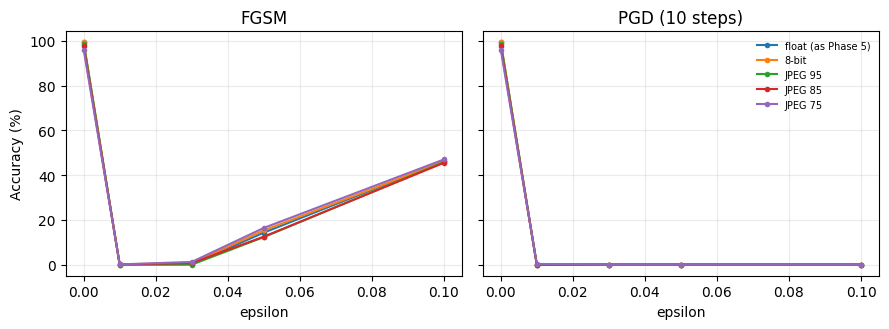

In [6]:
if RUN_ADV:
    import matplotlib.pyplot as plt
    fig, axs = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
    for ax, name in zip(axs, ['FGSM', 'PGD (10 steps)']):
        sub = adv_df[adv_df.attack.isin(['none', name])].sort_values('epsilon')
        for v in VARIANTS: ax.plot(sub.epsilon, sub[v] * 100, marker='o', ms=3, label=v)
        ax.set_title(name); ax.set_xlabel('epsilon'); ax.grid(alpha=.25)
    axs[0].set_ylabel('Accuracy (%)'); axs[1].legend(fontsize=7, frameon=False)
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/adversarial_realistic_handling.png', dpi=150); plt.show()

**How to read Part 1.** The `float` column should reproduce Table 4.19 (small differences are possible because the 1,000 images are chosen from an unsorted folder listing). If the `8-bit` column stays near 0%, the attack survives ordinary image saving. If `JPEG 75` brings the accuracy back up, the perturbation is fragile to compression for a non-adaptive attacker; an attacker who knows about the JPEG step can still adapt, so this is **not** evidence of defence.

## Part 2 — Control experiments: StyleGAN-only with the amount of data of Phase 6

In [7]:
%%writefile train_seeded.py
import argparse, os, json, random
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from tqdm import tqdm

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def get_dataloaders(data_dir, batch_size, seed, img_size=224):
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    train_tf = transforms.Compose([transforms.Resize((img_size, img_size)), transforms.RandomHorizontalFlip(), transforms.ToTensor(), normalize])
    val_tf = transforms.Compose([transforms.Resize((img_size, img_size)), transforms.ToTensor(), normalize])
    train_set = datasets.ImageFolder(f"{data_dir}/train", transform=train_tf)
    val_set = datasets.ImageFolder(f"{data_dir}/val", transform=val_tf)
    g = torch.Generator(); g.manual_seed(seed)
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=2, generator=g)
    val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False, num_workers=2)
    return train_loader, val_loader, train_set.class_to_idx

def build_model():
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    for p in m.parameters(): p.requires_grad = False
    for p in m.layer4.parameters(): p.requires_grad = True
    m.fc = nn.Linear(m.fc.in_features, 2)      # seeded random init
    return m

def run_epoch(model, loader, criterion, optimizer, device, train, quiet):
    model.train() if train else model.eval()
    tl, correct, total = 0.0, 0, 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for x, y in tqdm(loader, disable=quiet, desc="train" if train else "val"):
            x, y = x.to(device), y.to(device)
            if train: optimizer.zero_grad()
            out = model(x); loss = criterion(out, y)
            if train: loss.backward(); optimizer.step()
            tl += loss.item() * x.size(0); correct += (out.argmax(1) == y).sum().item(); total += y.size(0)
    return tl / total, correct / total

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_dir", required=True); ap.add_argument("--save_path", required=True)
    ap.add_argument("--seed", type=int, required=True); ap.add_argument("--epochs", type=int, default=5)
    ap.add_argument("--batch_size", type=int, default=64); ap.add_argument("--lr", type=float, default=1e-4)
    ap.add_argument("--quiet", action="store_true")
    a = ap.parse_args()
    set_seed(a.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    train_loader, val_loader, cidx = get_dataloaders(a.data_dir, a.batch_size, a.seed)
    print("Class mapping:", cidx, "| seed:", a.seed)
    model = build_model().to(device); criterion = nn.CrossEntropyLoss()
    params = [p for p in model.parameters() if p.requires_grad]
    print(f"Trainable parameters: {sum(p.numel() for p in params):,}")
    opt = torch.optim.Adam(params, lr=a.lr)
    best, log = 0.0, []
    for ep in range(a.epochs):
        tl, ta = run_epoch(model, train_loader, criterion, opt, device, True, a.quiet)
        vl, va = run_epoch(model, val_loader, criterion, opt, device, False, a.quiet)
        print(f"epoch {ep+1}/{a.epochs} train_loss={tl:.4f} train_acc={ta:.4f} val_loss={vl:.4f} val_acc={va:.4f}")
        log.append({"epoch": ep + 1, "train_loss": tl, "train_acc": ta, "val_loss": vl, "val_acc": va})
        if va > best:
            best = va; torch.save({"model_state": model.state_dict(), "class_to_idx": cidx}, a.save_path)
            print(f"  saved best (val_acc={va:.4f})")
    json.dump({"best_val_acc": best, "seed": a.seed, "log": log}, open(a.save_path + ".done", "w"))
    print("Done. Best val acc:", best)

if __name__ == "__main__":
    main()

Writing train_seeded.py


In [8]:
if RUN_CTRL:
    def link(src, dst):
        if not os.path.exists(dst): os.symlink(os.path.abspath(src), dst)
    def build_ctrl(name, n_per_class, n_val_per_class=4000, seed=42):
        rng = random.Random(seed)
        for split, src, n in [('train', styleGAN_train, n_per_class), ('val', styleGAN_val, n_val_per_class)]:
            for cls in ['real', 'fake']:
                d = f'data_{name}/{split}/{cls}'; os.makedirs(d, exist_ok=True)
                cd = find_class_dir(src, cls); files = sorted(os.listdir(cd)); rng.shuffle(files)
                for f in files[:n]: link(os.path.join(cd, f), os.path.join(d, f))
    for name, n in CONTROLS.items():
        build_ctrl(name, n)
        print(name, {s: {c: len(os.listdir(f'data_{name}/{s}/{c}')) for c in ['real', 'fake']} for s in ['train', 'val']})

ctrl60k {'train': {'real': 30000, 'fake': 30000}, 'val': {'real': 4000, 'fake': 4000}}
ctrl30k {'train': {'real': 15000, 'fake': 15000}, 'val': {'real': 4000, 'fake': 4000}}


In [9]:
if RUN_CTRL:
    for name in CONTROLS:
        for s in SEEDS:
            path = f'{CTRL_DIR}/{name}_seed{s}.pth'
            if os.path.exists(path + '.done'): print('exists, skipping:', path); continue
            print(f'===== training {name}, seed {s} =====')
            get_ipython().system(f'python train_seeded.py --data_dir data_{name} --save_path "{path}" --seed {s} --epochs 5 --batch_size 64 --lr 1e-4 --quiet')

===== training ctrl60k, seed 0 =====
Class mapping: {'fake': 0, 'real': 1} | seed: 0
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 179MB/s]
Trainable parameters: 8,394,754
epoch 1/5 train_loss=0.1793 train_acc=0.9254 val_loss=0.0989 val_acc=0.9606
  saved best (val_acc=0.9606)
epoch 2/5 train_loss=0.0635 train_acc=0.9763 val_loss=0.0758 val_acc=0.9721
  saved best (val_acc=0.9721)
epoch 3/5 train_loss=0.0382 train_acc=0.9865 val_loss=0.0866 val_acc=0.9704
epoch 4/5 train_loss=0.0293 train_acc=0.9890 val_loss=0.0674 val_acc=0.9760
  saved best (val_acc=0.9760)
epoch 5/5 train_loss=0.0234 train_acc=0.9915 val_loss=0.0556 val_acc=0.9810
  saved best (val_acc=0.9810)
Done. Best val acc: 0.981
===== training ctrl60k, seed 1 =====
Class mapping: {'fake': 0, 'real': 1} | seed: 1
Trainable parameters: 8,394,754
epoch 1/5 train_loss=0.1783 train_acc=0.9260 val_loss=0.0941 val_ac

In [10]:
if RUN_CTRL:
    from sklearn.metrics import roc_auc_score
    import pandas as pd
    std_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                                 transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])
    faceswap_test = find_split('data_raw_2', 'test')
    def subset_items(source_root, n_per_class, seed=99):          # identical to the frozen test suite
        rng = random.Random(seed); items = []
        for cls in ['real', 'fake']:
            cd = find_class_dir(source_root, cls); files = sorted(os.listdir(cd)); rng.shuffle(files)
            items += [(os.path.join(cd, f), int(cls == 'real')) for f in files[:n_per_class]]
        return items
    EVAL = {'stylegan': subset_items(styleGAN_test, 5000), 'faceswap': subset_items(faceswap_test, 5000)}
    class ItemsDS(Dataset):
        def __init__(self, items, tf): self.items, self.tf = items, tf
        def __len__(self): return len(self.items)
        def __getitem__(self, i):
            p, y = self.items[i]; return self.tf(Image.open(p).convert('RGB')), int(y)
    def load_resnet(path):
        ck = torch.load(path, map_location=device)
        m = models.resnet18(weights=None); m.fc = nn.Linear(m.fc.in_features, 2)
        m.load_state_dict(ck['model_state']); return m.to(device).eval(), ck['class_to_idx']
    @torch.no_grad()
    def p_real_for(m, real_idx, items):
        loader = DataLoader(ItemsDS(items, std_tf), batch_size=64, shuffle=False, num_workers=2)
        p, y = [], []
        for x, t in loader:
            p.append(torch.softmax(m(x.to(device)), 1)[:, real_idx].cpu().numpy()); y.append(t.numpy())
        return np.concatenate(p), np.concatenate(y)

    GROUPS = {'P2: StyleGAN 100,000 (Phase 10 seeds)': [f'{SEED_DIR}/p2_seed{s}.pth' for s in SEEDS]}
    for name, n in CONTROLS.items():
        GROUPS[f'Control {name}: StyleGAN {2 * n:,}'] = [f'{CTRL_DIR}/{name}_seed{s}.pth' for s in SEEDS]
    GROUPS['P6: StyleGAN 30,000 + face-swap 30,000 (Phase 10 seeds)'] = [f'{SEED_DIR}/p6_seed{s}.pth' for s in SEEDS]

    res = []
    for g, paths in GROUPS.items():
        for s, path in zip(SEEDS, paths):
            if not os.path.exists(path): print('missing:', path); continue
            m, cidx = load_resnet(path)
            for dom, items in EVAL.items():
                p, y = p_real_for(m, cidx['real'], items)
                res.append(dict(group=g, seed=s, domain=dom, acc=float(((p >= .5) == y).mean()), auc=float(roc_auc_score(y, p))))
            del m; torch.cuda.empty_cache()
    r = pd.DataFrame(res); r.to_csv(f'{OUT_DIR}/controls_per_seed.csv', index=False)
    def fmt(x, nd): return f'{x.mean():.{nd}f} ± {x.std(ddof=1):.{nd}f}' if len(x) > 1 else f'{x.mean():.{nd}f}'
    summary = (r.groupby(['group', 'domain']).agg(acc=('acc', lambda x: fmt(x, 4)), auc=('auc', lambda x: fmt(x, 4)), n_seeds=('seed', 'count')).reset_index())
    summary.to_csv(f'{OUT_DIR}/controls_summary.csv', index=False)
    from IPython.display import display
    display(summary)

,group,domain,acc,auc,n_seeds
0,"Control ctrl30k: StyleGAN 30,000",faceswap,0.4946 ± 0.0047,0.5057 ± 0.0232,3
1,"Control ctrl30k: StyleGAN 30,000",stylegan,0.9682 ± 0.0021,0.9961 ± 0.0000,3
2,"Control ctrl60k: StyleGAN 60,000",faceswap,0.4969 ± 0.0025,0.5221 ± 0.0052,3
3,"Control ctrl60k: StyleGAN 60,000",stylegan,0.9799 ± 0.0014,0.9982 ± 0.0004,3
4,"P2: StyleGAN 100,000 (Phase 10 seeds)",faceswap,0.4924 ± 0.0034,0.5024 ± 0.0139,3
5,"P2: StyleGAN 100,000 (Phase 10 seeds)",stylegan,0.9857 ± 0.0022,0.9991 ± 0.0003,3
6,"P6: StyleGAN 30,000 + face-swap 30,000 (Phase ...",faceswap,0.7908 ± 0.0067,0.8979 ± 0.0112,3
7,"P6: StyleGAN 30,000 + face-swap 30,000 (Phase ...",stylegan,0.9694 ± 0.0031,0.9958 ± 0.0003,3


**How to read Part 2.** Look at the StyleGAN rows.
- If `ctrl30k` (same number of StyleGAN images as Phase 6, no face-swap) is about as low as P6 (about 0.969 accuracy), the accuracy cost seen in Phase 6 is mostly due to **having fewer StyleGAN images**, not to mixing.
- If `ctrl30k` is clearly higher than P6, **mixing itself costs accuracy**.
- `ctrl60k` shows the effect of the *total* amount of data. On the face-swap rows the controls should be at chance (about 0.50 AUC): they never saw face swaps, and this confirms that the Phase 6 gain on face swaps comes from the face-swap images and not from the amount of data.

### What to send back
Paste (1) the table of Part 1 (`adv_df`) and (2) the summary table of Part 2. I will add both to the thesis: Part 1 to Section 4.6.2 and Part 2 to Section 4.3.4, and remove the matching limitations.